In [2]:
import pandas as pd

data_fp = "../../data/mces-data/biostructures.csv"
df = pd.read_csv(data_fp)
df

,smiles,inchi_key_1
0,C1COCCN1C2=NC(=NC(=N2)NC3=CC(=C(C=C3)C=CC4=C(C...,KFDYZSPFVRTLML
1,CCOC1=C(C=CC(=C1)C=NNC(=O)COC2=C(C=CC(=C2)C)C(...,HINREHSUCWWBNO
2,CCOC1=C(C=CC(=C1)C=NNC(=O)COC2=C(C=CC(=C2)C(C)...,XSJXTRKBEZABIM
3,CC1=CC=CC=C1N2C(=NN=C2SCC(=O)NC3=CC(=C(C=C3)Cl...,RGEDPHNWBSQUKZ
4,CC1=CC=CC=C1N2C(=NN=C2SCC(=O)NC3=C(C=CC=C3Cl)C...,RPFGFTBJBUHWDA
...,...,...
718092,CC(=O)OC1=C2C(=C3C(CN(C3=C1)C(=O)C4=CC5=CC(=C(...,FHZABVWOHCBVED
718093,CC(C)(C)C1=CC=C(C=C1)C2=NN=C(N2C3=CC=CC=C3)SCC...,MJYGYQSLIBPSCA
718094,CC(=NNC(=O)CSC1=NN=C(N1C2=CC=CC=C2)C3=CC=C(C=C...,BOBKKASWDWHSNN
718095,C1C[N+]2(CCC1C(C2)C(C3=CC=CC=C3)(C4=CC=CC=C4)O...,JHQFDHSPOYHZMH


In [3]:
# Check for duplicates by inchi_key_1
duplicates = df.duplicated(subset='inchi_key_1', keep=False)
print(f"Number of duplicated rows by inchi_key_1: {duplicates.sum()}")

# Show the duplicated entries
duplicated_df = df[duplicates].sort_values('inchi_key_1')
print(f"\nDuplicated entries:\n{duplicated_df}")

# Remove duplicates, keeping the first occurrence
df_dedup = df.drop_duplicates(subset='inchi_key_1', keep='first')
print(f"\nOriginal shape: {df.shape}")
print(f"After removing duplicates: {df_dedup.shape}")
print(f"Number of duplicates removed: {df.shape[0] - df_dedup.shape[0]}")

Number of duplicated rows by inchi_key_1: 0

Duplicated entries:
Empty DataFrame
Columns: [smiles, inchi_key_1]
Index: []

Original shape: (718097, 2)
After removing duplicates: (718097, 2)
Number of duplicates removed: 0


In [4]:
mol_df_fp = "../../data/mces-data/mol_df.pkl"
mol_df = pd.read_pickle(mol_df_fp)
mol_df

,smiles_org,idx,smiles,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,[2H]C1(C([N+]2=CC=CC=C2C3=CC=CC=[N+]31)([2H])[...,0,NaN,SYJFEGQWDCRVNX,c1cc[n+]2c(c1)-c1cccc[n+]1CC2,C12H12N2+2,InChI=1S/C12H12N2/c1-3-7-13-9-10-14-8-4-2-6-12...,188.266407,188.124058,18,20,2,True,0
1,[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([...,1,NaN,KWTSXDURSIMDCE,c1ccccc1,C9H13N,"InChI=1S/C9H13N/c1-8(10)7-9-5-3-2-4-6-9/h2-6,8...",138.228305,138.123630,13,13,0,True,0
2,[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([...,2,NaN,KWTSXDURSIMDCE,c1ccccc1,C9H13N,"InChI=1S/C9H13N/c1-8(10)7-9-5-3-2-4-6-9/h2-6,8...",138.228305,138.123630,13,13,0,True,0
3,[As]#[In],3,NaN,RPQDHPTXJYYUPQ,,AsIn,InChI=1S/As.In,189.740000,189.825475,2,1,0,True,0
4,B1(C2CCCC1CCC2)B3C4CCCC3CCC4,4,NaN,IYDIZBOKVLHCQZ,C1CC2CCCC(C1)B2B1C2CCCC1CCC2,C16H28B2,InChI=1S/C16H28B2/c1-5-13-7-2-8-14(6-1)17(13)1...,242.024000,242.237712,18,21,0,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63432,P#[P+],63432,NaN,GSQBFINVLXKPNU,,P2+,InChI=1S/P2/c1-2/q+1,61.948000,61.946975,2,1,1,True,1
63433,[SiH2](Cl)Cl,63433,NaN,MROCJMGDEKINLD,,H2Cl2Si,InChI=1S/Cl2H2Si/c1-3-2/h3H2,101.008000,99.930282,3,2,0,True,0
63434,S[S],63434,NaN,PYPQFOINVKFSJD,,HS2,InChI=1S/HS2/c1-2/h1H,65.142000,64.951967,2,1,0,True,1
63435,S=[Sb](=S)S[Sb](=S)=S,63435,NaN,PPKVREKQVQREQD,,S5Sb2,InChI=1S/5S.2Sb,403.855000,401.667986,7,6,0,True,0


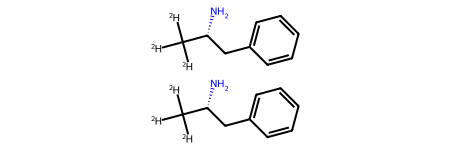

In [6]:
from rdkit import Chem
Chem.MolFromSmiles('[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N')  # Example to check RDKit functionality

In [ ]:
from fragnnet.utils.data_utils import mol_from_smiles
# Example to check if mol_from_smiles works correctly
mol = mol_from_smiles('[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N')
mol